<a href="https://colab.research.google.com/github/aaniesfaizie-ship-it/superstore-sales-analysis/blob/main/Superstore_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Superstore Sales Analysis
**Author:** Anies Faizie | **Tools:** Python, pandas, NumPy, SQL (SQLite), Matplotlib

## Objective
Analyze 4 years of retail orders from a US superstore to find what drives sales and profit, and recommend actions to improve profitability.

## Business questions
1. Which categories and sub-categories make the most money, and which lose money?
2. How do sales change over time? Is there seasonality?
3. Which regions perform best and worst?
4. How do discounts affect profit?
5. Who are the top customers, and which customer segment is most valuable?
6. Which customers are loyal, and which are at risk of leaving? (RFM segmentation)

**Dataset:** [Superstore Dataset on Kaggle](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final) (~10,000 orders, 21 columns)

## 1. Setup

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
print('Libraries loaded')

Libraries loaded


## 2. Load the data
Run this cell and click **Choose Files** to upload the CSV you downloaded from Kaggle (a .zip also works).

In [25]:
import os
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except ImportError:
    file_name = 'Sample - Superstore.csv'   # when running outside Colab

df = None
for enc in ['utf-8', 'latin-1', 'cp1252']:
    try:
        df = pd.read_csv(file_name, encoding=enc)
        break
    except UnicodeDecodeError:
        continue

print('Loaded:', file_name)
df.head()

Saving archive.zip to archive (1).zip
Loaded: archive (1).zip


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


## 3. First look at the data

In [26]:
print('Rows, columns:', df.shape)
print()
df.info()

Rows, columns: (9994, 21)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-n

In [27]:
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate rows: 0


## 4. Data cleaning
- Standardize column names
- Convert order and ship dates to proper date types
- Remove duplicate rows
- Create new columns: year, month, profit margin, days to ship

In [28]:
rows_before = len(df)

# Standardize column names: 'Sub-Category' -> 'sub_category'
df.columns = (df.columns.str.strip().str.lower()
              .str.replace('-', '_').str.replace(' ', '_'))

# Convert dates
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', errors='coerce')
df['ship_date'] = pd.to_datetime(df['ship_date'], format='mixed', errors='coerce')

# Remove duplicates and rows with no sales value
df = df.drop_duplicates()
df = df.dropna(subset=['sales', 'profit', 'order_date'])

# New columns
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.to_period('M')
df['profit_margin'] = df['profit'] / df['sales'] * 100
df['days_to_ship'] = (df['ship_date'] - df['order_date']).dt.days

print(f'Rows before: {rows_before:,} | after cleaning: {len(df):,}')
print('Date range:', df['order_date'].min().date(), 'to', df['order_date'].max().date())
df.head(3)

Rows before: 9,994 | after cleaning: 9,994
Date range: 2014-01-03 to 2017-12-30


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,year,month,profit_margin,days_to_ship
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2016,2016-11,16.00,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2016,2016-11,30.00,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,2016,2016-06,47.00,4


## 5. Key metrics

In [29]:
total_sales = df['sales'].sum()
total_profit = df['profit'].sum()
overall_margin = total_profit / total_sales * 100
n_orders = df['order_id'].nunique()
n_customers = df['customer_id'].nunique()

print(f'Total sales:      ${total_sales:,.0f}')
print(f'Total profit:     ${total_profit:,.0f}')
print(f'Profit margin:    {overall_margin:.1f}%')
print(f'Orders:           {n_orders:,}')
print(f'Customers:        {n_customers:,}')
print(f'Avg order value:  ${total_sales / n_orders:,.0f}')

Total sales:      $2,297,201
Total profit:     $286,397
Profit margin:    12.5%
Orders:           5,009
Customers:        793
Avg order value:  $459


## 6. Q1: Which categories and sub-categories are most and least profitable?

In [30]:
cat = (df.groupby('category')[['sales', 'profit']].sum()
         .assign(margin_pct=lambda t: t['profit'] / t['sales'] * 100)
         .sort_values('sales', ascending=False))
cat

,sales,profit,margin_pct
category,,,
Technology,"836,154.03","145,454.95",17.40
Furniture,"741,999.80","18,451.27",2.49
Office Supplies,"719,047.03","122,490.80",17.04


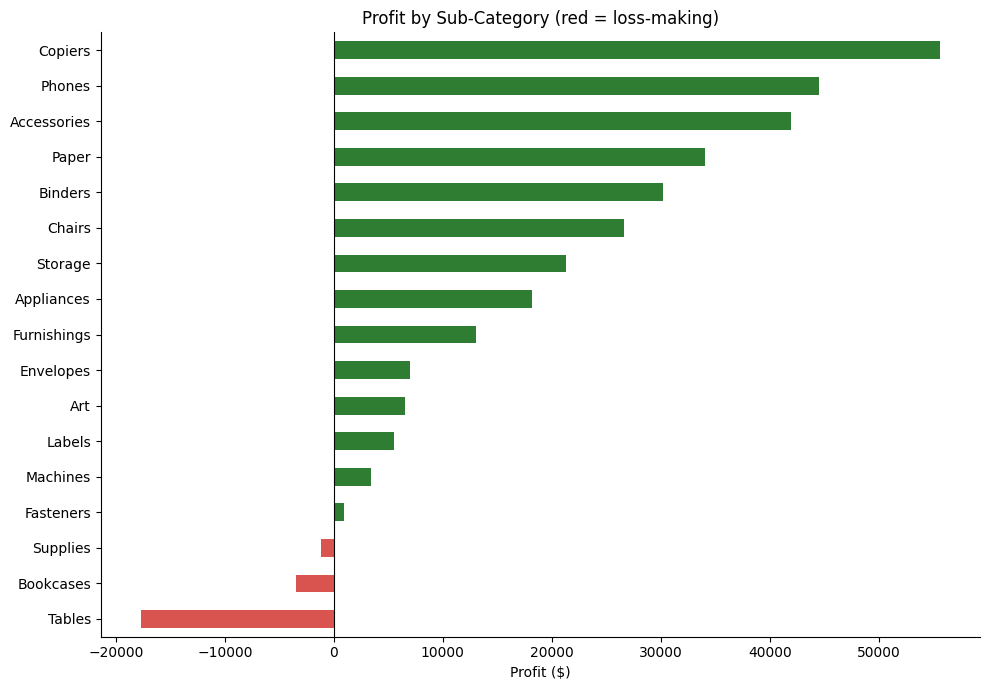

Loss-making sub-categories:
                  sales     profit
sub_category                      
Tables       206,965.53 -17,725.48
Bookcases    114,880.00  -3,472.56
Supplies      46,673.54  -1,189.10


In [31]:
sub = (df.groupby('sub_category')[['sales', 'profit']].sum()
         .sort_values('profit'))

colors = ['#d9534f' if p < 0 else '#2e7d32' for p in sub['profit']]
ax = sub['profit'].plot(kind='barh', color=colors, figsize=(10, 7))
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Profit by Sub-Category (red = loss-making)')
ax.set_xlabel('Profit ($)')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('profit_by_subcategory.png', dpi=150)
plt.show()

loss_makers = sub[sub['profit'] < 0]
print('Loss-making sub-categories:')
print(loss_makers)

## 7. Q2: How do sales change over time?

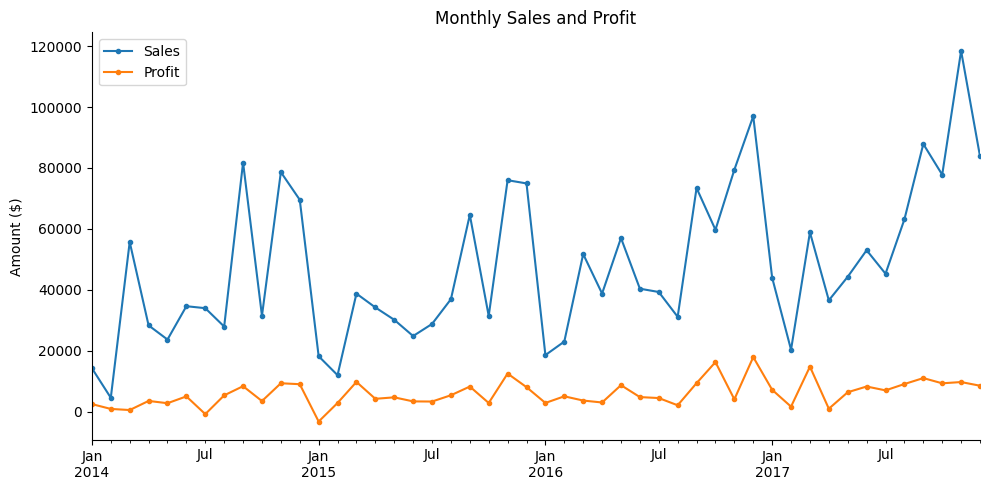

Sales by year:
year
2014   484,247.50
2015   470,532.51
2016   609,205.60
2017   733,215.26
Name: sales, dtype: float64

Year-over-year growth (%):
year
2014     NaN
2015   -2.80
2016   29.50
2017   20.40
Name: sales, dtype: float64


In [32]:
monthly = df.groupby('month')[['sales', 'profit']].sum()
monthly.index = monthly.index.to_timestamp()

ax = monthly['sales'].plot(marker='o', markersize=3, label='Sales')
monthly['profit'].plot(ax=ax, marker='o', markersize=3, label='Profit')
ax.set_title('Monthly Sales and Profit')
ax.set_ylabel('Amount ($)')
ax.set_xlabel('')
ax.legend()
plt.tight_layout()
plt.savefig('monthly_trend.png', dpi=150)
plt.show()

yearly = df.groupby('year')['sales'].sum()
print('Sales by year:')
print(yearly)
print()
print('Year-over-year growth (%):')
print((yearly.pct_change() * 100).round(1))

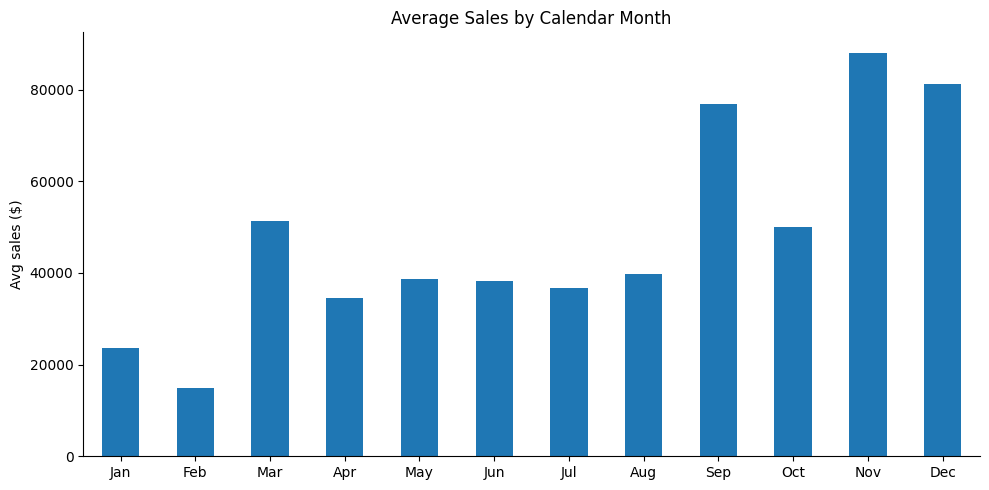

In [33]:
# Seasonality: average sales for each calendar month across all years
by_month = df.groupby(df['order_date'].dt.month)['sales'].sum() / df['year'].nunique()
by_month.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'][:len(by_month)]

ax = by_month.plot(kind='bar', color='#1f77b4')
ax.set_title('Average Sales by Calendar Month')
ax.set_ylabel('Avg sales ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('seasonality.png', dpi=150)
plt.show()

## 8. Q3: Which regions perform best?

             sales     profit  margin_pct
region                                   
West    725,457.82 108,418.45       14.94
East    678,781.24  91,522.78       13.48
South   391,721.91  46,749.43       11.93
Central 501,239.89  39,706.36        7.92


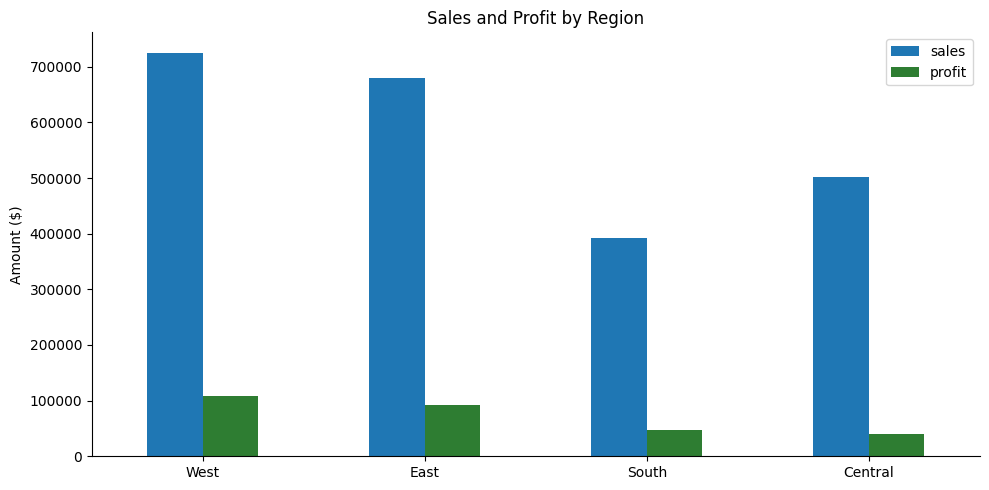

In [34]:
region = (df.groupby('region')[['sales', 'profit']].sum()
            .assign(margin_pct=lambda t: t['profit'] / t['sales'] * 100)
            .sort_values('profit', ascending=False))
print(region)

ax = region[['sales', 'profit']].plot(kind='bar', color=['#1f77b4', '#2e7d32'])
ax.set_title('Sales and Profit by Region')
ax.set_ylabel('Amount ($)')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('region_performance.png', dpi=150)
plt.show()

In [35]:
# Least profitable states
state_profit = df.groupby('state')['profit'].sum().sort_values()
print('5 least profitable states:')
print(state_profit.head(5))

5 least profitable states:
state
Texas            -25,729.36
Ohio             -16,971.38
Pennsylvania     -15,559.96
Illinois         -12,607.89
North Carolina    -7,490.91
Name: profit, dtype: float64


## 9. Q4: How do discounts affect profit?

               orders        sales     profit  margin_pct
discount_band                                            
No discount      4798 1,087,908.47 320,987.60       29.51
1-20%            3803   846,522.24 100,785.47       11.91
21-40%            460   234,137.90 -35,817.47      -15.30
Above 40%         933   128,632.25 -99,558.59      -77.40


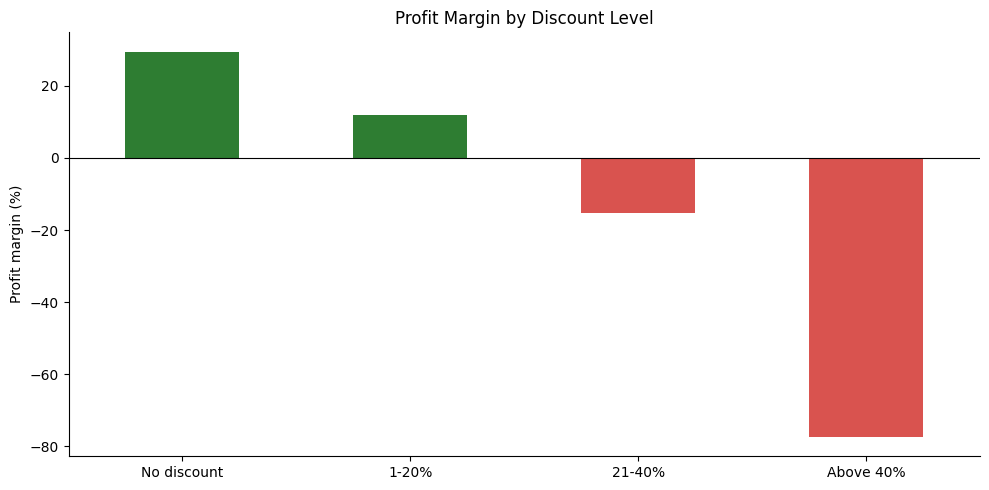

Correlation between discount and profit: -0.22


In [36]:
bins = [-0.01, 0, 0.2, 0.4, 1]
labels = ['No discount', '1-20%', '21-40%', 'Above 40%']
df['discount_band'] = pd.cut(df['discount'], bins=bins, labels=labels)

disc = (df.groupby('discount_band', observed=True)
          .agg(orders=('order_id', 'count'), sales=('sales', 'sum'), profit=('profit', 'sum'))
          .assign(margin_pct=lambda t: t['profit'] / t['sales'] * 100))
print(disc)

colors = ['#d9534f' if m < 0 else '#2e7d32' for m in disc['margin_pct']]
ax = disc['margin_pct'].plot(kind='bar', color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Profit Margin by Discount Level')
ax.set_ylabel('Profit margin (%)')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('discount_vs_margin.png', dpi=150)
plt.show()

print('Correlation between discount and profit:', round(df['discount'].corr(df['profit']), 2))

## 10. Q5: Customers and segments, answered with SQL
Loading the cleaned data into an SQLite database and answering questions with SQL queries.

In [37]:
conn = sqlite3.connect(':memory:')
sql_cols = ['order_id', 'order_date', 'customer_id', 'customer_name', 'segment',
            'region', 'category', 'sub_category', 'sales', 'quantity', 'discount', 'profit']
df[sql_cols].astype({'order_date': str}).to_sql('orders', conn, index=False)

query = '''
SELECT segment,
       COUNT(DISTINCT customer_id)                    AS customers,
       ROUND(SUM(sales), 0)                           AS total_sales,
       ROUND(SUM(profit), 0)                          AS total_profit,
       ROUND(SUM(sales) / COUNT(DISTINCT order_id), 0) AS avg_order_value
FROM orders
GROUP BY segment
ORDER BY total_sales DESC;
'''
segments = pd.read_sql(query, conn)
segments

,segment,customers,total_sales,total_profit,avg_order_value
0,Consumer,409,"1,161,401.00","134,119.00",449.00
1,Corporate,236,"706,146.00","91,979.00",466.00
2,Home Office,148,"429,653.00","60,299.00",473.00


In [38]:
query = '''
SELECT customer_name,
       COUNT(DISTINCT order_id) AS orders,
       ROUND(SUM(sales), 0)     AS total_sales,
       ROUND(SUM(profit), 0)    AS total_profit
FROM orders
GROUP BY customer_name
ORDER BY total_sales DESC
LIMIT 10;
'''
top_customers = pd.read_sql(query, conn)
top_customers

,customer_name,orders,total_sales,total_profit
0,Sean Miller,5,"25,043.00","-1,981.00"
1,Tamara Chand,5,"19,052.00","8,981.00"
2,Raymond Buch,6,"15,117.00","6,976.00"
3,Tom Ashbrook,4,"14,596.00","4,704.00"
4,Adrian Barton,10,"14,474.00","5,445.00"
5,Ken Lonsdale,12,"14,175.00",807.00
6,Sanjit Chand,9,"14,142.00","5,757.00"
7,Hunter Lopez,6,"12,873.00","5,622.00"
8,Sanjit Engle,11,"12,209.00","2,651.00"
9,Christopher Conant,5,"12,129.00","2,177.00"


In [39]:
# Share of total sales coming from the top 20% of customers
cust_sales = df.groupby('customer_id')['sales'].sum().sort_values(ascending=False)
top_20_share = cust_sales.head(int(len(cust_sales) * 0.2)).sum() / cust_sales.sum() * 100
print(f'Top 20% of customers generate {top_20_share:.1f}% of total sales')

Top 20% of customers generate 48.0% of total sales


## 11. Q6: RFM customer segmentation
Scoring every customer on three things companies use to understand their buyers:
- **Recency:** how many days since their last order (lower is better)
- **Frequency:** how many orders they placed
- **Monetary:** how much they spent in total

Each is scored 1 to 4 (4 = best), and customers are grouped into segments a marketing team can act on.

In [40]:
snapshot_date = df['order_date'].max() + pd.Timedelta(days=1)

rfm = df.groupby('customer_id').agg(
    recency=('order_date', lambda d: (snapshot_date - d.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('sales', 'sum'),
)

# Score 1-4 using quartiles. rank() avoids errors when many customers share a value.
rfm['r_score'] = pd.qcut(rfm['recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm['f_score'] = pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['m_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)

def assign_segment(row):
    if row['r_score'] >= 3 and row['f_score'] >= 3 and row['m_score'] >= 3:
        return 'Champions'      # bought recently, often, and spend a lot
    elif row['r_score'] >= 3 and row['f_score'] >= 3:
        return 'Loyal'          # recent and frequent, lower spend
    elif row['r_score'] >= 3:
        return 'Promising'      # recent but not yet frequent
    elif row['f_score'] >= 3 or row['m_score'] >= 3:
        return 'At Risk'        # used to buy a lot, but not recently
    else:
        return 'Lost'           # not recent, rarely bought, low spend

rfm['segment'] = rfm.apply(assign_segment, axis=1)
rfm.head()

,recency,frequency,monetary,r_score,f_score,m_score,segment
customer_id,,,,,,,
AA-10315,185,5,"5,563.56",1,1,4,At Risk
AA-10375,20,9,"1,056.39",4,4,1,Loyal
AA-10480,260,4,"1,790.51",1,1,2,Lost
AA-10645,56,6,"5,086.93",3,2,4,Promising
AB-10015,416,3,886.16,1,1,1,Lost


           customers  avg_days_since_order  avg_orders  total_sales  share_of_sales_pct
segment                                                                                
Champions        176                 33.20        8.80   802,935.50               35.00
Loyal             62                 31.10        7.80    98,896.30                4.30
Promising        159                 35.00        4.50   357,340.20               15.60
At Risk          217                212.50        7.20   856,287.30               37.30
Lost             179                322.60        3.90   181,741.60                7.90


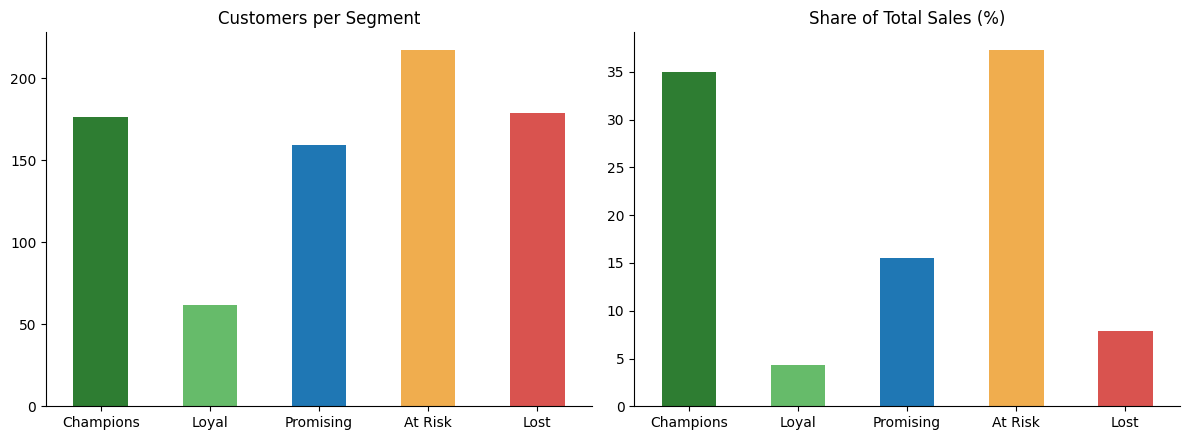

In [41]:
order = ['Champions', 'Loyal', 'Promising', 'At Risk', 'Lost']
rfm_summary = (rfm.groupby('segment')
                 .agg(customers=('recency', 'count'),
                      avg_days_since_order=('recency', 'mean'),
                      avg_orders=('frequency', 'mean'),
                      total_sales=('monetary', 'sum'))
                 .reindex(order).dropna())
rfm_summary['share_of_sales_pct'] = rfm_summary['total_sales'] / rfm_summary['total_sales'].sum() * 100
print(rfm_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
seg_colors = ['#2e7d32', '#66bb6a', '#1f77b4', '#f0ad4e', '#d9534f'][:len(rfm_summary)]
rfm_summary['customers'].plot(kind='bar', ax=axes[0], color=seg_colors)
axes[0].set_title('Customers per Segment')
axes[0].set_xlabel('')
rfm_summary['share_of_sales_pct'].plot(kind='bar', ax=axes[1], color=seg_colors)
axes[1].set_title('Share of Total Sales (%)')
axes[1].set_xlabel('')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('rfm_segments.png', dpi=150)
plt.show()

## 12. Key insights
This cell writes the main findings from the numbers calculated above.

In [42]:
best_cat = cat['profit'].idxmax()
worst_sub = sub['profit'].idxmin()
best_region = region['profit'].idxmax()
worst_region = region['profit'].idxmin()
peak_month = by_month.idxmax()
high_disc = disc.iloc[-1]
no_disc = disc.iloc[0]
top_segment = segments.iloc[0]

insights = [
    f"Overall: ${total_sales:,.0f} in sales and ${total_profit:,.0f} profit, a {overall_margin:.1f}% margin.",
    f"{best_cat} is the most profitable category, earning ${cat.loc[best_cat, 'profit']:,.0f} at a {cat.loc[best_cat, 'margin_pct']:.1f}% margin.",
    f"{len(loss_makers)} sub-categories lose money. {worst_sub} is the worst, losing ${-sub.loc[worst_sub, 'profit']:,.0f}.",
    f"Sales peak in {peak_month}, so stock and marketing should be planned around this season.",
    f"{best_region} is the most profitable region; {worst_region} is the weakest, at a {region.loc[worst_region, 'margin_pct']:.1f}% margin.",
    f"Orders with no discount earn a {no_disc['margin_pct']:.1f}% margin, while discounts above 40% produce a {high_disc['margin_pct']:.1f}% margin.",
    f"The {top_segment['segment']} segment brings in the most sales (${top_segment['total_sales']:,.0f}).",
    f"The top 20% of customers generate {top_20_share:.1f}% of all sales.",
    f"RFM: {int(rfm_summary.loc['Champions', 'customers'])} Champions drive {rfm_summary.loc['Champions', 'share_of_sales_pct']:.1f}% of sales, while {int(rfm_summary.loc['At Risk', 'customers'])} At-Risk customers (avg {rfm_summary.loc['At Risk', 'avg_days_since_order']:.0f} days since last order) hold {rfm_summary.loc['At Risk', 'share_of_sales_pct']:.1f}% of sales.",
]
for i, s in enumerate(insights, 1):
    print(f'{i}. {s}')

1. Overall: $2,297,201 in sales and $286,397 profit, a 12.5% margin.
2. Technology is the most profitable category, earning $145,455 at a 17.4% margin.
3. 3 sub-categories lose money. Tables is the worst, losing $17,725.
4. Sales peak in Nov, so stock and marketing should be planned around this season.
5. West is the most profitable region; Central is the weakest, at a 7.9% margin.
6. Orders with no discount earn a 29.5% margin, while discounts above 40% produce a -77.4% margin.
7. The Consumer segment brings in the most sales ($1,161,401).
8. The top 20% of customers generate 48.0% of all sales.
9. RFM: 176 Champions drive 35.0% of sales, while 217 At-Risk customers (avg 213 days since last order) hold 37.3% of sales.


## 13. Recommendations
1. **Cap discounts at around 20%.** Heavy discounts are the biggest driver of losses. Orders above that level lose money on average.
2. **Review loss-making sub-categories.** Check pricing, shipping costs, and discount policy for the products that lose money. Consider bundling them with profitable items.
3. **Fix the weakest region and states.** Investigate why some states lose money, especially whether high discounts are being used there.
4. **Plan for the peak season.** Increase inventory and run campaigns ahead of the strongest months.
5. **Reward Champions.** A small group of customers drives a large share of sales, so a loyalty program could protect that revenue.
6. **Win back At-Risk customers.** They used to buy often or spend a lot but have gone quiet. A targeted offer or reminder campaign costs far less than finding new customers.

## Skills demonstrated
Data cleaning, feature engineering, exploratory data analysis, SQL aggregation, RFM customer segmentation, data visualization, and turning analysis into business recommendations.